In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import log10, log
from statsmodels.formula.api import ols

sns.set_theme('talk')

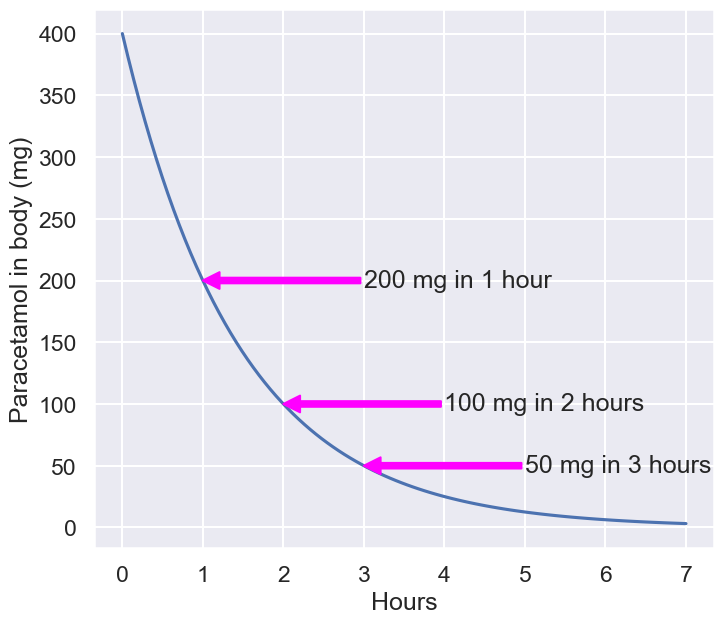

In [36]:
fig, ax = plt.subplots(figsize=(8, 7))

x = np.linspace(0, 7, 100)
y = lambda x, y0, T: y0*np.exp(-np.log(2)*x/T)

T = 1

ax.plot(x, y(x, 400, T))
ax.set_xlabel('Hours')
ax.set_ylabel('Paracetamol in body (mg)');

for t, c in enumerate((200, 100, 50)):
    x = t+1
    ax.annotate(f'{c} mg in {x} hour'+('' if x == 1 else 's'), (x, c), (x+2, c), arrowprops={'color':'Magenta'}, va='center')

fig.savefig('paracetamol.svg', bbox_inches='tight')

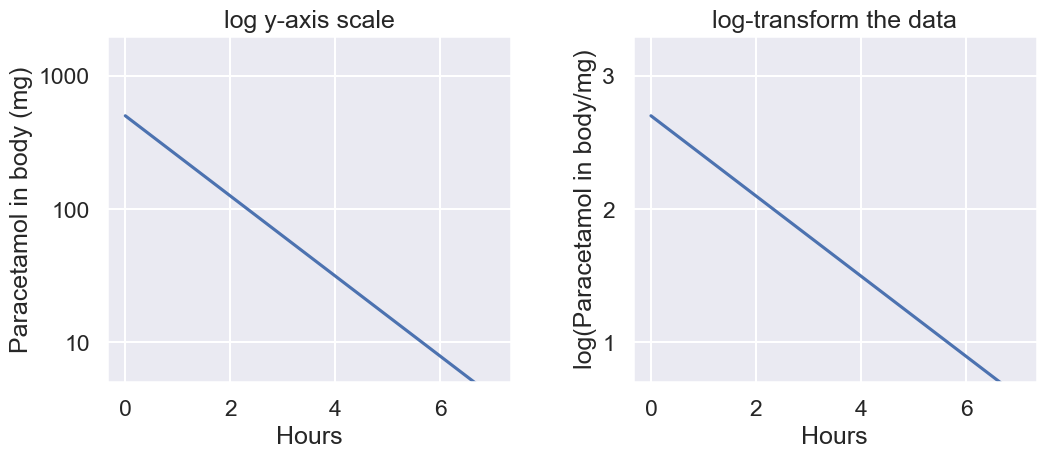

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
plt.subplots_adjust(wspace=0.3)

x = np.linspace(0, 7, 100)
y = lambda x, y0, T: y0*np.exp(-np.log(2)*x/T)

T = 1
y0 = 500

ax = axs[0]
ax.plot(x, y(x, y0, T))
ax.set_xlabel('Hours')
ax.set_ylabel('Paracetamol in body (mg)');
ax.set_ylim(5, 2000)
ax.set_yscale('log')
ax.set_yticks((10, 100, 1000), (10, 100, 1000))
ax.set_title('log y-axis scale')

ax = axs[1]
ax.plot(x, np.log10(y(x, y0, T)))
ax.set_xlabel('Hours')
ax.set_ylabel('log(Paracetamol in body/mg)');
ax.set_ylim(np.log10(5), np.log10(2000))
ax.set_yticks((1, 2, 3))
ax.set_title('log-transform the data')

fig.savefig('paracetamol_log.svg', bbox_inches='tight')

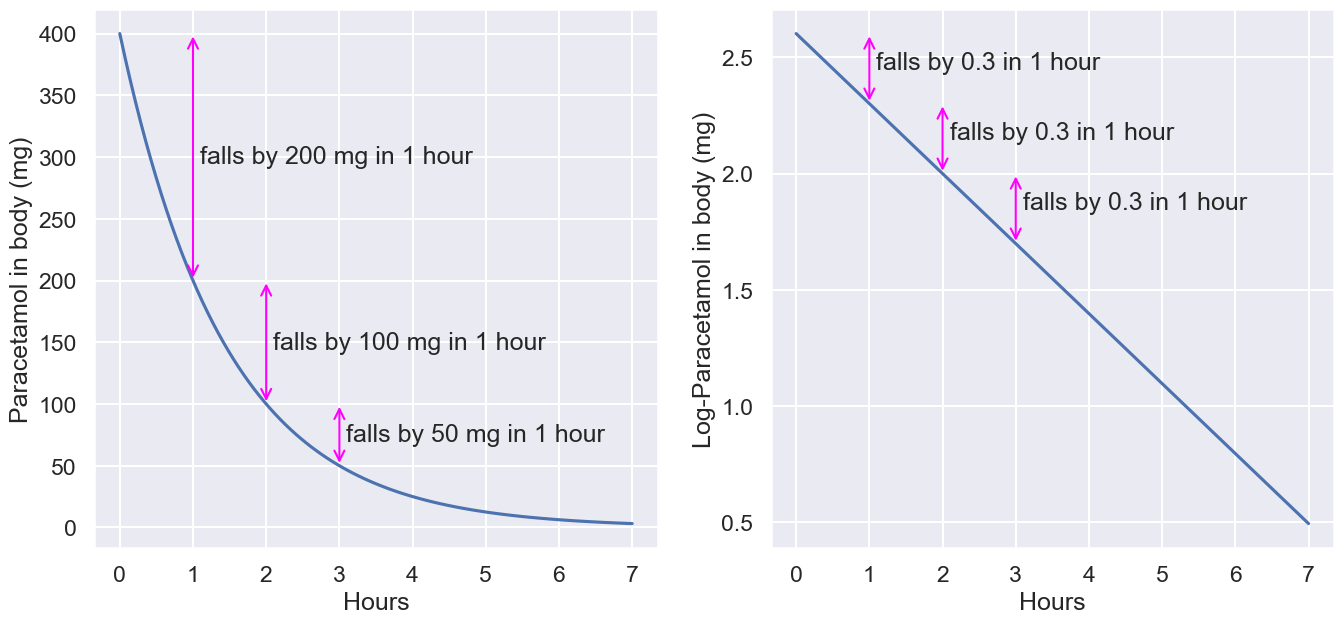

In [38]:
fig, axs = plt.subplots(1, 2, figsize=(16, 7))

x = np.linspace(0, 7, 100)
y = lambda x, y0, T: y0*np.exp(-np.log(2)*x/T)

T = 1
y0 = 400

ax = axs[0]
ax.plot(x, y(x, y0, T))
ax.set_xlabel('Hours')
ax.set_ylabel('Paracetamol in body (mg)');

for i, c in enumerate((400, 200, 100)):
    t = i+1
    ax.annotate('', (t, c), (t, c/2), arrowprops=dict(arrowstyle="<->", color='Magenta'))
    ax.text(t, c*0.75, f' falls by {c-c/2:.0f} mg in 1 hour', va='center');

ax = axs[1]
ax.plot(x, log10(y(x, y0, T)))
ax.set_xlabel('Hours')
ax.set_ylabel('Log-Paracetamol in body (mg)');

for t, c in enumerate((400, 200, 100)):
    x = t+1
    ax.annotate('', (x, log10(c)), (x, log10(c/2)), arrowprops=dict(arrowstyle="<->", color='Magenta'))
    ax.text(x, log10(c*0.75), f' falls by {log10(c)-log10(c/2):.1f} in 1 hour', va='center');


fig.savefig('paracetamol_linear.svg')

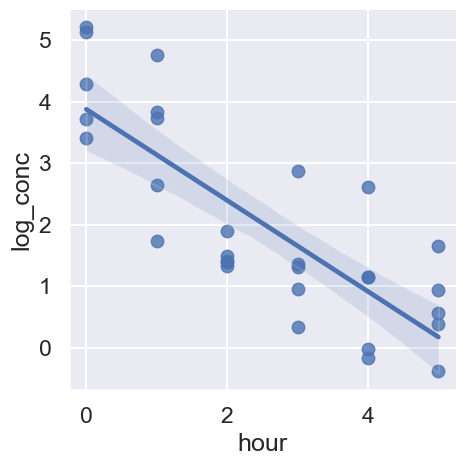

In [39]:
drugs = pd.read_csv('../Data/drug_data.csv')
drugA = drugs.query('drug == "A"').copy()
drugA['log_conc'] = log(drugA['concentration'])
sns.lmplot(data=drugA, x='hour', y='log_conc');
plt.savefig('drugA_log_conc_time.svg')


In [40]:
formula = 'log_conc ~ hour'
fit = ols(formula, drugA).fit()

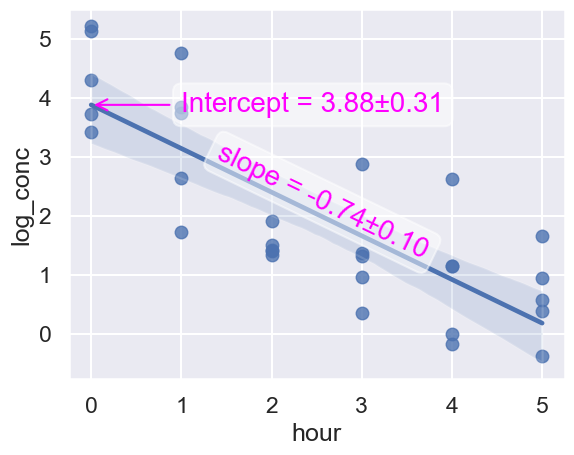

In [41]:
from numpy import arctan, pi
mu = fit.params
se = fit.bse
c = mu['Intercept']
m = mu['hour']
se_c = se['Intercept']
se_m = se['hour']
f = lambda x: c+m*x
ax = sns.regplot(data=drugA, x='hour', y='log_conc');
ax.annotate(f'Intercept = {c:.2f}±{se_c:.2f}', (0, c), (1, c),
    arrowprops={'arrowstyle':'->', 'color':'Magenta'},
    fontsize=20, color='Magenta', va='center',
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
ax.text(2.5, f(2.5), f'slope = {m:.2f}±{se_m:.2f}',
    color='Magenta', fontsize=20, va='bottom', ha='center',
    rotation=360*arctan(m)/(2*pi), rotation_mode='anchor',
    transform_rotates_text=True,
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
plt.savefig('drugA.svg', bbox_inches='tight')

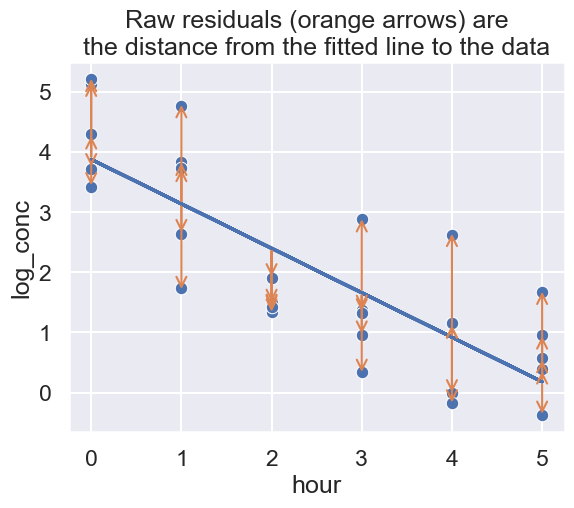

In [42]:
drugA['regression'] = fit.fittedvalues
drugA['residuals'] = fit.resid_pearson
ax = sns.scatterplot(data=drugA, x='hour', y='log_conc')

ax.plot('hour', 'regression', data=drugA)
for _, r in drugA.iterrows():
    ax.annotate('', (r['hour'], r['regression']), (r['hour'], r['regression']+r['residuals']), arrowprops={'arrowstyle':'<-', 'color':'C1'})
ax.set_title('Raw residuals (orange arrows) are\nthe distance from the fitted line to the data');
plt.savefig('residuals.svg', bbox_inches='tight')

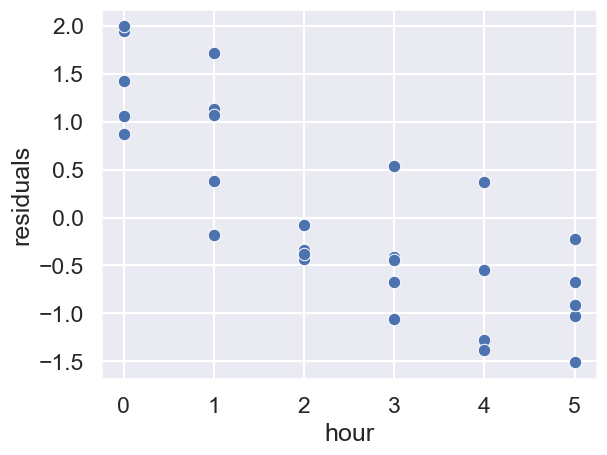

In [43]:
d1 = drugA.copy()
formula = 'log_conc ~ 1'
fit1 = ols(formula, d1).fit()
d1['residuals'] = fit1.resid_pearson
sns.scatterplot(data=d1, x='hour', y='residuals');
plt.savefig('residuals_poor.svg', bbox_inches='tight')

In [44]:
from numpy import arctan, pi, sqrt
drugs['log_conc'] = log(drugs['concentration']).dropna()

formula = 'log_conc ~ drug*hour'
fit = ols(formula, drugs).fit()

cov = fit.cov_params()
secA = sqrt(cov.iloc[0, 0])
secB = sqrt(cov.iloc[0:2, 0:2].sum().sum())
semA = sqrt(cov.iloc[2, 2])
semB = sqrt(cov.iloc[2:4, 2:4].sum().sum())

mu = fit.params
se = fit.bse
cA = mu['Intercept']
delta_c = mu['drug[T.B]']
cB = cA + delta_c
mA = mu['hour']
delta_m = mu['drug[T.B]:hour']
mB = mA + delta_m
se_c = se['Intercept']
se_delta_c = se['drug[T.B]']
se_m = se['hour']
se_delta_m = se['drug[T.B]:hour']

fA = lambda x: cA+mA*x
fB = lambda x: cB+mB*x


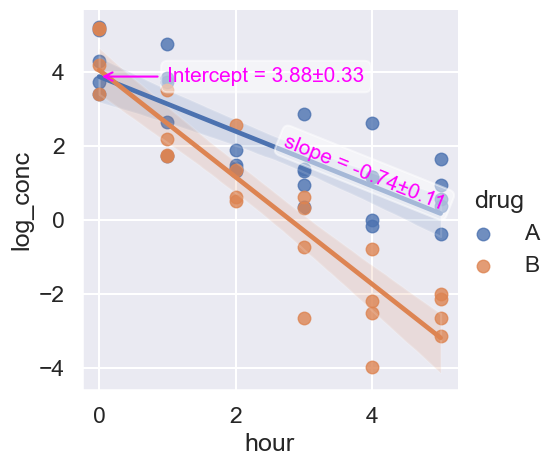

In [45]:
g = sns.lmplot(data=drugs, x='hour', y='log_conc', hue='drug');
ax = g.axes[0][0]
ax.annotate(f'Intercept = {c:.2f}±{se_c:.2f}', (0, c), (1, c),
    arrowprops={'arrowstyle':'->', 'color':'Magenta'},
    fontsize=15, color='Magenta', va='center',
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
ax.text(5, f(5), f'slope = {m:.2f}±{se_m:.2f}',
    color='Magenta', fontsize=15, va='bottom', ha='right',
    rotation=360*arctan(m)/(2*pi), rotation_mode='anchor',
    transform_rotates_text=True,
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
plt.savefig('drug_refA.svg', bbox_inches='tight')

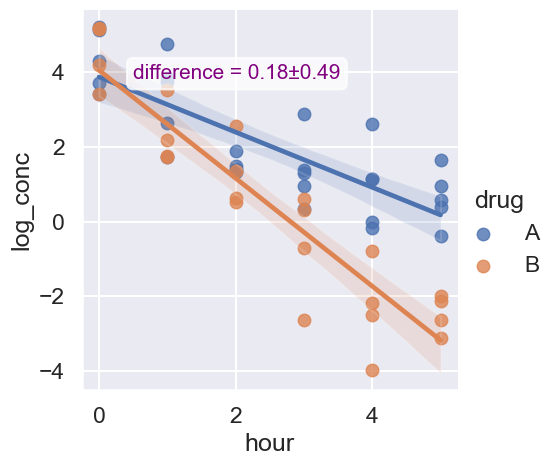

In [46]:
g = sns.lmplot(data=drugs, x='hour', y='log_conc', hue='drug');
ax = g.axes[0][0]
# ax.annotate(f'Intercept = {cA:.2f}±{secA:.2f}', (0, cA), (1, cA),
#     arrowprops={'arrowstyle':'simple', 'color':'Magenta'},
#     fontsize=15, color='Magenta', va='center',
#     bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.75)
# )
# ax.annotate(f'Intercept = {cB:.2f}±{secB:.2f}', (0, cB), (1, cB-4),
#     arrowprops={'color':'Magenta'},
#     fontsize=15, color='Magenta', va='center',
#     bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.75)
# )
# ax.annotate('', (0, cA), (0, cB),
#     arrowprops={'arrowstyle':'<->', 'color':'Purple', 'lw':5, 'shrinkA':0, 'shrinkB':0}
# )
ax.annotate(f'difference = {delta_c:.2f}±{se_delta_c:.2f}', (0,0), (0.5, 0.5*(cA+cB)),
            va='center', fontsize=15, color='Purple',
            bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.75)
)
plt.savefig('drugs_D_intercept.svg', bbox_inches='tight')

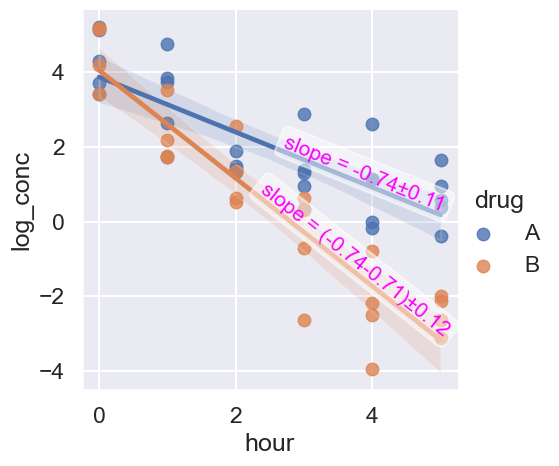

In [47]:
g = sns.lmplot(data=drugs, x='hour', y='log_conc', hue='drug');
ax = g.axes[0][0]
ax.text(5, fA(5), f'slope = {mA:.2f}±{semA:.2f}',
    color='Magenta', fontsize=15, va='bottom', ha='right',
    rotation=360*arctan(m)/(2*pi), rotation_mode='anchor',
    transform_rotates_text=True,
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
ax.text(5, fB(5), f'slope = ({mA:.2f}{delta_m:.2f})±{semB:.2f}',
    color='Magenta', fontsize=15, va='bottom', ha='right',
    rotation=360*arctan(mB)/(2*pi), rotation_mode='anchor',
    transform_rotates_text=True,
    bbox=dict(boxstyle="round", ec='w', fc='w', alpha=0.5)
)
plt.savefig('drugs_D_slopes.svg', bbox_inches='tight')

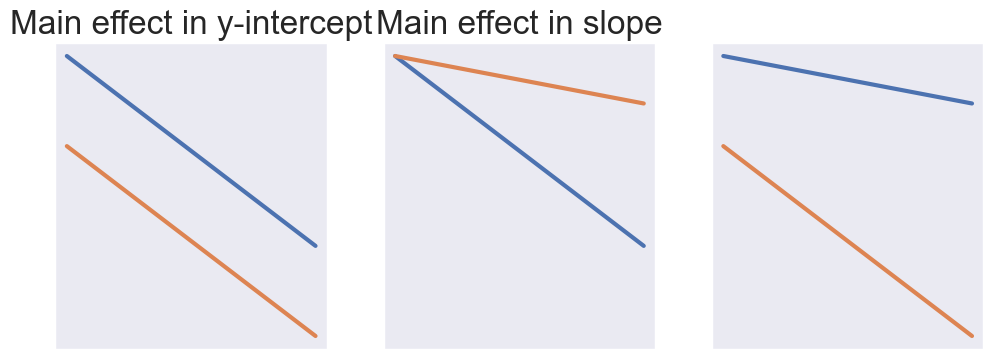

In [48]:
sns.set_theme('poster')
x = np.linspace(0, 7, 100)
y = lambda x, y0, T: y0*np.exp(-np.log(2)*x/T)

fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

ax = axs[0]
ax.plot(x, log(y(x, 400, 1)))
ax.plot(x, log(y(x, 40, 1)))
ax.set_title('Main effect in y-intercept')

ax = axs[1]
ax.plot(x, log(y(x, 400, 1)))
ax.plot(x, log(y(x, 400, 4)))
ax.set_title('Main effect in slope')

ax = axs[2]
ax.plot(x, log(y(x, 400, 4)))
ax.plot(x, log(y(x, 40, 1)))

for ax in axs.flatten():
    ax.set_xticks([])
    ax.set_yticks([])